Implements raster and vector analysis using the TI-City model results and its spatial inputs.

### Authorship
@author: Alexandre Pereira Santos <br>
alexandre.santos(at)lmu.de<br>
- usespandas, geopandas, rasterio, rasterstats
- may include content from LLMs

### Features
1. Load ASCII files with ti-city NetLogo output
2. Assemble the ASCIIs as n-dimensional numpy vector, with n=number of runs
3. Load pre-calculated exposure metrics (TBD: segment exposure across RCP scenarios)
4. Calculate statistics for all runs (mean exposure, exposure per SEP, and vulnerability index [vuln = exposure degree * SEP class]
5. Plot stats as 
   1. Exposure vs. vulnerability map (t=2050) for each scenario
   2. Vulnerability index per scenario (line plot?), time on the x-axis

# Imports

In [6]:
import pandas as pd
import geopandas as gpd

import os
from pathlib import Path
#import fnmatch
#import shutil

import numpy as np
import random 
import matplotlib.pyplot as plt
#import matplotlib.colors as mcolors
#import matplotlib.patches as mpatches
import natsort

#from shapely.geometry.polygon import Polygon
#from shapely.geometry import MultiLineString, LineString
#import json

import rasterio
from rasterio.mask import mask
from rasterio.plot import show, show_hist, plotting_extent
from rasterio.warp import reproject, calculate_default_transform, Resampling
from rasterio.features import dataset_features
import rasterstats
#from libpysal.weights import lat2W, Rook
#from esda.moran import Moran

from SALib.sample import morris as morris_sample
from SALib.analyze import morris as morris_analyze

from ti_city_00_helper_functions import *
from ti_city_10_calibration_fuzzy_fom_validation_module import *

# init

In [10]:
#%%time

case_city = 'JAK' #MUM MAN JAK
drop_path = r'C:\\Sciebo\\05_GIS\\' # adjust this to match the path on your computer, e.g. 'D:\\Dropbox\\x\\PostDoc\\GIS' or 'C:\\Users\\x\\Dropbox\\x\\PostDoc\\GIS'
external_data_path = Path(r'C:\\Sciebo\\00_data') # adjust this to match the path on your computer, e.g. 'D:\\Dropbox\\x\\PostDoc\\00_data' or 'C:\\Users\\x\\Dropbox\\x\\PostDoc\\00_data'
## ascii150_arcgis_path = Path(r"D:\\Dropbox\\x\\PostDoc\ASCII_150m") deprecated, ignore

#input a vector and a raster file for each city
AOI_path = Path(f'{drop_path}\\{case_city}\\processed\\')
AOI_file = f'{case_city}_LIM_AOI_reference_150m_A.shp' # APS: updated AOI 01.08.2024

AOI_gdf = gpd.read_file(AOI_path / AOI_file) #.to_crs(epsg=4326)
AOI_gdf_4326 = AOI_gdf.to_crs(epsg=4326) 

ref_raster_path = Path(f'../data/processed/{case_city}_LIM_reference_AOI_150m.tif')
ref_raster_150_path = Path(f'../data/processed/{case_city}_LIM_reference_AOI_150m.tif')

raw_path = Path(f'\\{case_city}\\raw\\')
interim_path = Path(drop_path + f'{case_city}\\interim\\')
processed_path = Path(drop_path + f'{case_city}\\processed\\')
external_path = Path(drop_path + f'{case_city}\\external\\')
model_inputs_30m_path = Path(drop_path + f'{case_city}\\model_inputs\\TIFF_30m\\')
model_inputs_150m_path = Path(drop_path + f'{case_city}\\model_inputs\\TIFF_150m\\')
model_inputs_SLEUTH_150m_path = Path(drop_path + f'{case_city}\\model_inputs\\TIFF_SLEUTH_150m')
model_outputs_path = Path(drop_path + f'{case_city}\\model_outputs\\') 
ascii150_path = Path(drop_path + f'\\{case_city}\\model_inputs\\ASCII_150m')
ascii150_SLEUTH_path = Path(drop_path + f'\\{case_city}\\model_inputs\\ASCII_SLEUTH_150m')
ti_city_model_path = Path(f'../model/{case_city}/')
ti_city_in_path = Path(f'../model/{case_city}/data/in/')
ti_city_out_path = Path(f'../model/{case_city}/data/out/')
ref_raster_sleuth_path = model_inputs_SLEUTH_150m_path / (case_city + '_URB_SLEUTH_input_2022.tif' )

if case_city == 'MUM':
    gadm_var = 'NAME_3'
    calibration_years = [2015,2025]
    simulation_years = [2025, 2050]

if case_city == 'MAN':    
    gadm_var = 'NAME_2'
    calibration_years = [2015,2025]
    simulation_years = [2025, 2050]

if case_city == 'JAK':
    gadm_var = 'NAME_3'
    calibration_years = [2000,2025]
    simulation_years = [2025, 2050]

# read the reference raster
with rasterio.open(ref_raster_path,'r') as src: # APS 20.08.2025 using the 150 m raster
    ref_raster = src
    ref_meta = src.meta
    ref_height, ref_width, ref_area = get_transform(ref_raster)

# suppress deprecation warnings
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn


# defs

Urban early raster: (680, 772)
Urban late raster: (680, 772)


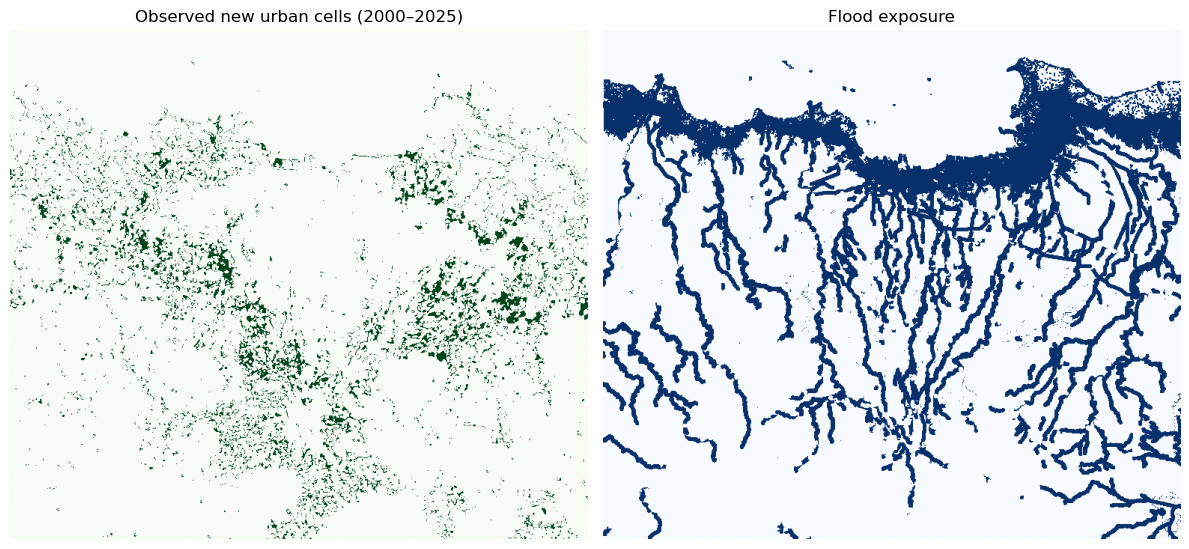

In [12]:
def load_ascii_files(scenarios, scenario_path, load_mode = 'final', results_folder=model_outputs_path, file_name_template = 'expansion_income_t', export_tiff=False, export_path=model_outputs_path, silent=False):
    results_dict = {}
    for scenario in scenarios:
        path = results_folder / scenario_path[scenario]
        if not silent:
            print(f'Processing content from: {scenario} at {path}')
        # example: "D:\GIT\ti-city-model\model\JAK\data\out\R037\expansion_income_t0.asc"
        # list and count the files in this folder
        ascii_files = [f for f in os.listdir(path) if f.endswith('.asc')]
        ascii_files = natsort.natsorted(ascii_files)  # Natural sorting
        #print(ascii_files)
        # build a dict containing the ASCII files with the structure scenario > n-runs
        results_dict[scenario] = {}#{'list': ascii_files}
        if load_mode == 'final':
            # load only the last tick (the final result) for each scenario
            print(f'Loading only the final tick for scenario: {scenario}')
            if ascii_files:
                last_file = ascii_files[-1]
                
                key = Path(last_file).stem
                if key.startswith(file_name_template):
                    key = key[len(file_name_template):]
                    if not silent:
                        print(f'Extracted key: {key} from file: {last_file}')
                else:
                    key = key.split('t')[-1]
                    if not silent:
                        print(f'Extracted key-1: {key} from file: {last_file}')
                url = path / last_file
                with rasterio.open(url, 'r') as src:
                    array = src.read(1)
                    array_meta = src.meta
                results_dict[scenario][key] = array
        elif load_mode == 'all':
            # load all ticks for each scenario
            print(f'Loading all ticks for scenario: {scenario}')
            for file in ascii_files:
                key = Path(file).stem
                if key.startswith(file_name_template):
                    key = key[len(file_name_template):]
                    if not silent:
                        print(f'Extracted key: {key} from file: {file}')
                else:
                    key = key.split('t')[-1]
                    if not silent:
                        print(f'Extracted key-1: {key} from file: {file}')

                url = path / file
                with rasterio.open(url, 'r') as src:
                    array = src.read(1)
                    array_meta = src.meta
                results_dict[scenario][key] = array
    if export_tiff:
        for scenario, runs in results_dict.items():
            dir_path = export_path / scenario_path_dict[scenario]
            dir_path.mkdir(parents=True, exist_ok=True)
            for run_key, raster in runs.items():
                try:
                    tick = int(run_key)
                    tick_str = f"{tick:03d}"
                except Exception:
                    tick_str = run_key
                file_name = f"{case_city}_TI-City_results_{scenario}_t{tick_str}.tif"
                url = dir_path / file_name
                print(url)
                export_raster(
                    raster=raster.astype('int16'),
                    url=url,
                    data_type=rasterio.int16,
                    ref_raster_path=ref_raster_150_path
                )
    return results_dict

def compile_scenarios_table(
    results_dict,
    baseline_dict,
    exposure_raster,
    start_year = simulation_years[0],
    cell_area=0.150 * 0.150,
    export_results_table=True,
    export_path=model_outputs_path
):
    agent_class_dict = {
        'na': 0, 'deprived': 1, 'low': 2, 'mid': 3,
        'high': 4, 'urban_first_year': 5
    }
    descriptive_dict = {}

    for scenario, series in results_dict.items():
        sorted_keys = natsort.natsorted(series.keys())
        descriptive_dict[scenario] = {}

        for key in sorted_keys:
            raster = series[key]
            year = start_year + int(key)

            stats_dict = {}
            stats_dict['New urban cells'] = np.count_nonzero(
                (raster > 0) & (raster <= 4)
            )
            stats_dict['Total Urban Area'] = np.round(
                np.sum(raster > 0) * cell_area, 2
            )
            stats_dict['Urban Area Exposed to Flooding'] = np.round(
                np.sum((raster > 0) & (exposure_raster > 0)) * cell_area, 2
            )
            stats_dict['Total New Urban Area'] = np.round(
                stats_dict['Total Urban Area']
                - np.sum(raster == agent_class_dict['urban_first_year']) * cell_area,
                2
            )
            stats_dict['New Urban Area Exposed to Flooding'] = np.round(
                stats_dict['Urban Area Exposed to Flooding']
                - np.sum(
                    (raster == agent_class_dict['urban_first_year'])
                    & (exposure_raster > 0)
                ) * cell_area,
                2
            )

            # Compare this result with each baseline raster.
            for baseline_name, baseline_series in baseline_dict.items():
                if key in baseline_series:
                    baseline_raster = baseline_series[key]
                elif len(baseline_series) == 1:
                    baseline_raster = next(iter(baseline_series.values()))
                else:
                    raise KeyError(
                        f"No baseline raster for tick {key!r} in "
                        f"{baseline_name!r}."
                    )

                if baseline_raster.shape != raster.shape:
                    raise ValueError(
                        f"Raster shape mismatch for baseline {baseline_name!r}: "
                        f"{baseline_raster.shape} != {raster.shape}"
                    )

                new_cells = (baseline_raster > 0) & (baseline_raster <= 4)
                stats_dict[f'new_cells_{baseline_name}'] = int(
                    np.count_nonzero(new_cells)
                )
                stats_dict[f'new_area_{baseline_name}'] = np.round(
                    np.count_nonzero(new_cells) * cell_area, 2
                )

            for class_name, class_id in agent_class_dict.items():
                if class_name == 'na':
                    continue

                stats_dict[f'Urban Area ({class_name})'] = np.round(
                    np.sum(raster == class_id) * cell_area, 2
                )
                stats_dict[f'Urban Area Exposed ({class_name})'] = np.round(
                    np.sum((raster == class_id) & (exposure_raster > 0))
                    * cell_area,
                    2
                )

            descriptive_dict[scenario][year] = stats_dict

    rows = []
    for scenario, years in descriptive_dict.items():
        for year, stats in years.items():
            row = {"Scenario": scenario, "Year": year}
            row.update(stats)
            rows.append(row)

    results_table = pd.DataFrame(rows)
    results_table = results_table.sort_values(
        ["Scenario", "Year"]
    ).reset_index(drop=True)

    results_table["Total Urban Area"] = results_table[
        [
            "Urban Area (deprived)",
            "Urban Area (low)",
            "Urban Area (mid)",
            "Urban Area (high)"
        ]
    ].sum(axis=1)

    for class_name in ("deprived", "low", "mid", "high"):
        results_table[f"Urban Area ({class_name}) Percentage"] = (
            results_table[f"Urban Area ({class_name})"]
            / results_table["Total Urban Area"] * 100
        ).round(2)

    exposure_columns = [
        f"Urban Area Exposed ({class_name})"
        for class_name in ("deprived", "low", "mid", "high")
    ]
    results_table["Urban Area Exposed (total)"] = results_table[
        exposure_columns
    ].sum(axis=1)

    for class_name in ("deprived", "low", "mid", "high"):
        results_table[f"Urban Area Exposed ({class_name}) Percentage"] = (
            results_table[f"Urban Area Exposed ({class_name})"]
            / results_table["Urban Area Exposed (total)"] * 100
        ).round(2)

    if export_results_table:
        output_file = export_path / (
            f"{case_city}_urban_exposed_areas_analysis_"
            f"{scenario_path_dict[scenario_list[0]].rstrip('/')}_"
            f"{scenario_path_dict[scenario_list[-1]].rstrip('/')}.xlsx"
        )
        results_table.to_excel(output_file, index_label="ID")
        print(f"Results table exported to {output_file}")

    return results_table

exposure_areas_path = None
if case_city == 'MAN':
    file_name = case_city + '_HYD_25_year_flooding_surgeSSA1_reclass_150m.tif'
    exposure_areas_path = model_inputs_150m_path / file_name
elif case_city == 'JAK':
    file_name = case_city + '_HYD_flood_hazard_150m.tif'
    exposure_areas_path = interim_path / file_name
elif case_city == 'MUM':
    file_name = case_city + '_HYD_flood_hazard_150m.tif'
    exposure_areas_path = interim_path / file_name

with rasterio.open(exposure_areas_path,'r') as src:
    exposure_raster = src.read(1)
    exposure_raster_meta = src.meta
    # we have to adjust the area of the exposure raster to that of the results
#print('Exposure raster:', exposure_raster.shape)
#plot_unique_value_raster(exposure_raster)
#plot_continuous_raster(exposure_raster)
#plot_unique_value_raster(exposure_raster, title='Areas exposed to flooding (25 years return) and storm surge')

# load urbanisation reference rasters for the calibration years
# early = first year of calibration period calibration_years[0]
# late = last year of calibration period calibration_years[1]

#urban_early_file = case_city + f'_URB_urbanisation_{calibration_years[0]}_GHSL_150m.tif'
#urban_early_path = model_inputs_150m_path / urban_early_file

urban_early_path = ti_city_in_path / 'urban_early.asc'

with rasterio.open(urban_early_path,'r') as src:
    urban_early_raster = src.read(1)
    urban_early_raster_meta = src.meta
print('Urban early raster:', urban_early_raster.shape)

#urban_late_file = case_city + f'_URB_urbanisation_{calibration_years[1]}_GHSL_150m.tif'
#urban_late_path = model_inputs_150m_path / urban_late_file
urban_late_path = ti_city_in_path / 'urban_late.asc'

with rasterio.open(urban_late_path,'r') as src:
    urban_late_raster = src.read(1)
    urban_late_raster_meta = src.meta
print('Urban late raster:', urban_late_raster.shape)

# Extract observed new-urban cells (2000-2025) on the 150 m AOI grid
new_cells_observed = observed_new_from_rasters(urban_late_raster, urban_early_raster).astype(np.uint8)

#plot new_cells_observed
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(new_cells_observed, cmap='Greens', vmin=0, vmax=1)
axes[0].set_title(
    f'Observed new urban cells ({calibration_years[0]}–{calibration_years[1]})'
)
axes[0].axis('off')

axes[1].imshow(exposure_raster > 0, cmap='Blues', vmin=0, vmax=1)
axes[1].set_title('Flood exposure')
axes[1].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# this import loads the calibration scenario (S0a) 
# and three baseline scenarios for comparison: random (S0b), 
# edge-growth (S0c), and road-based growth (S0d)
scenario_name_dict = {
    's0a': 'Calibration scenario',
    's_random': 'Random scenario',
    's_edge': 'Edge growth scenario',
    's_roadbound': 'Road growth scenario'
}

scenario_list = ['s0'] #, 'S0b', 'S0c', 'S0d']
scenario_path_dict = {'s0': 'R121/'} # consider the output_folder

baseline_list = ['s_random', 's_edge', 's_roadbound']
baseline_path_dict = {
    baseline_list[0]: 'R118/',
    baseline_list[1]: 'R119/',
    baseline_list[2]: 'R120/'
}

results_dict = load_ascii_files(
    scenarios = scenario_list,
    scenario_path = scenario_path_dict,
    results_folder=ti_city_out_path,
    file_name_template='expansion_income_t',
    export_tiff=False,
    export_path=model_outputs_path,
    silent=False)
baseline_dict = load_ascii_files(
    scenarios = baseline_list,
    scenario_path = baseline_path_dict,
    results_folder=ti_city_out_path,
    file_name_template='expansion_income_t',
    export_tiff=False,
    export_path=model_outputs_path,
    silent=False)
#baseline_dict['Observed'] = {'025':new_cells_observed}
results_table = compile_scenarios_table(
    results_dict = results_dict,
    baseline_dict = baseline_dict,
    exposure_raster = exposure_raster,
    start_year = calibration_years[0],
    cell_area=0.150*0.150, 
    export_results_table=True, 
    export_path=model_outputs_path)

Processing content from: s0 at ..\model\JAK\data\out\R121
Loading only the final tick for scenario: s0
Extracted key: 025 from file: expansion_income_t025.asc
Processing content from: s_random at ..\model\JAK\data\out\R118
Loading only the final tick for scenario: s_random
Extracted key: 025 from file: expansion_income_t025.asc
Processing content from: s_edge at ..\model\JAK\data\out\R119
Loading only the final tick for scenario: s_edge
Extracted key: 025 from file: expansion_income_t025.asc
Processing content from: s_roadbound at ..\model\JAK\data\out\R120
Loading only the final tick for scenario: s_roadbound
Extracted key: 025 from file: expansion_income_t025.asc
Results table exported to C:\Sciebo\05_GIS\JAK\model_outputs\JAK_urban_exposed_areas_analysis_R121_R121.xlsx


# 4. Calibration procedures

## 4.1 Figure of merit (FoM)

In [ ]:
from notebooks.ti_city_10_calibration_fuzzy_fom_validation_module import *

# observed new-urban cells: 0/1 int array (urban_late & ~urban_early)
new_cells_observed = observed_new_from_rasters(
    urban_late = urban_late_raster,
    urban_early = urban_early_raster)

# ---- model scenarios ----
fom_table = evaluate_scenario_fom(
    results_dict = results_dict,
    obs_new = new_cells_observed,
    initial_urban = urban_early_raster > 0,
    start_year = calibration_years[0],
    per_tick = 'final',
    variant = 'hits_only',
    case_city = case_city,
    cell_km = 0.150,
    silent = False)

# ---- baselines (same rules, same obs, same grid) ----
baseline_fom_table = evaluate_scenario_fom(
    results_dict = baseline_dict,
    obs_new = new_cells_observed,
    initial_urban = urban_early_raster > 0,
    start_year = calibration_years[0],
    per_tick = 'final',
    variant = 'hits_only',
    case_city = case_city,
    cell_km = 0.150,
    silent = False)
# ---- normalise model rows against the strongest baseline per metric ----
fom_table = normalize_against_baselines(
    fom_table = fom_table,
    baseline_fom_table = baseline_fom_table)

# ---- join onto the (freshly re-initialised) results table ----
results_table = append_validation_to_results_table(
    results_table = results_table,
    fom_table = fom_table,
    export_results_table = False)

Evaluating against 29,559 observed new-urban cells (excl. JAK initial urban & invalid cells).
  S0a_major roads t025: N_sim=28,860 FoM=0.304 fFoM_t1=0.403 fFoM_t2=0.450 fFoM_t3=0.480 fFoM_t5=0.516
  S0b_all roads t025: N_sim=25,720 FoM=0.241 fFoM_t1=0.404 fFoM_t2=0.456 fFoM_t3=0.488 fFoM_t5=0.526
  S0d_random w 3 t025: N_sim=25,703 FoM=0.243 fFoM_t1=0.407 fFoM_t2=0.459 fFoM_t3=0.490 fFoM_t5=0.526
  S0d_random w 6 t025: N_sim=25,732 FoM=0.241 fFoM_t1=0.407 fFoM_t2=0.459 fFoM_t3=0.490 fFoM_t5=0.525
  S0e_random w 9 t025: N_sim=25,713 FoM=0.241 fFoM_t1=0.409 fFoM_t2=0.461 fFoM_t3=0.491 fFoM_t5=0.527
Evaluating against 29,559 observed new-urban cells (excl. JAK initial urban & invalid cells).
  S_random t025: N_sim=28,258 FoM=0.049 fFoM_t1=0.268 fFoM_t2=0.426 fFoM_t3=0.486 fFoM_t5=0.519
  S_edge t025: N_sim=24,556 FoM=0.242 fFoM_t1=0.522 fFoM_t2=0.595 fFoM_t3=0.628 fFoM_t5=0.655
  S_roadbound t025: N_sim=27,590 FoM=0.109 fFoM_t1=0.388 fFoM_t2=0.496 fFoM_t3=0.534 fFoM_t5=0.558


In [16]:
# export the results table to Excel
suffix = f"{scenario_path_dict[scenario_list[0]].rstrip('/')}_{scenario_path_dict[scenario_list[-1]].rstrip('/')}_{calibration_years[0]}_{calibration_years[1]}"
output_file = model_outputs_path / (f"{case_city}_validation_results_{suffix}.xlsx")
results_table.to_excel(output_file, index=False)
print(f"Validation results table exported to {output_file}")

Validation results table exported to C:\Sciebo\05_GIS\JAK\model_outputs\JAK_validation_results_R094_R094_2000_2025.xlsx


In [ ]:
from notebooks.ti_city_10_calibration_fuzzy_fom_validation_module import *

# 1. Observed new-urban cells (2000-2025) on the 150 m AOI grid
new_cells_observed = observed_new_from_rasters(urban_late_raster, urban_early_raster) 

fom_table = evaluate_scenario_fom(
    results_dict = results_dict, 
    obs_new = new_cells_observed,
    initial_urban = urban_early_raster > 0,
    start_year=calibration_years[0],
    per_tick = 'final',
    variant = 'hits_only',
    case_city = case_city,
    cell_km = 0.150,
    silent = False
    )

# 3. Normalise against the baselines
fom_table = normalize_against_baselines(fom_table,
    baseline_scenarios=[baseline_list[0], baseline_list[1],baseline_list[2]])  # your scenario names

# 4. Join the FoM columns onto your existing results table
results_table = append_validation_to_results_table(results_table, fom_table,
                                                    export_path=model_outputs_path)

Evaluating against 29,559 observed new-urban cells (excl. JAK initial urban & invalid cells).
  S0a t025: N_sim=28,889 FoM=0.275 fFoM_t1=0.373 fFoM_t2=0.422 fFoM_t3=0.454 fFoM_t5=0.490
  S0b t025: N_sim=28,910 FoM=0.051 fFoM_t1=0.256 fFoM_t2=0.413 fFoM_t3=0.478 fFoM_t5=0.510
  S0c t025: N_sim=28,901 FoM=0.561 fFoM_t1=0.721 fFoM_t2=0.753 fFoM_t3=0.768 fFoM_t5=0.776
  S0d t025: N_sim=28,901 FoM=0.135 fFoM_t1=0.194 fFoM_t2=0.237 fFoM_t3=0.274 fFoM_t5=0.342


ValueError: None of the baseline scenarios found in fom_table: ['S_random', 'S_roadbound', 'S_edge']

In [ ]:
# from fuzzy_fom_validation import *
from notebooks.ti_city_10_calibration_fuzzy_fom_validation_module import *

# 1. Observed new-urban cells (2000-2025) on the 150 m AOI grid
obs_new = urban_late_raster

# 2. Score every tick of the calibration run
fom_table = evaluate_scenario_fom(
    results_dict = results_dict, 
    obs_new = obs_new,
    initial_urban = urban_early_raster,
    start_year = calibration_years[0],  # 2000 for JAK
    per_tick = 'final',
    variant = 'hits_only',
    case_city = case_city,
    cell_km = 0.150,
    silent = False
    )              # reproduces the earlier 45.2% soft-FoM
                                      # use variant='full' going forward (symmetric)


#null_row = null_fom_baseline(obs_new, eligible_mask=~urban_early_raster, n_seeds=5)

# 4. Join the FoM columns onto your existing results table
results_table = append_validation_to_results_table(results_table, fom_table,
                                                    export_path=model_outputs_path)

## 4.2 Wasserstein distance 
(earth mover's distance, EMD)

## 4.3 L1 distance

## 4.4 Patch metrics

## 4.5 Scalar objective (summary)

# (optional) Compare results with HDI calibration data

In [54]:
admin3_file = interim_path / (case_city + '_POP_HDI_component_estimates_ADMlvl3_A.gpkg')
admin3_gdf = gpd.read_file(admin3_file)

In [55]:
# calculate the exposed area for each admin 3 unit
admin3_gdf['exp_surface'] = rasterstats.zonal_stats(admin3_gdf, exposure_raster, affine=exposure_raster_meta['transform'], stats=['sum'], nodata=0, geojson_out=False, raster_out=False)
admin3_gdf['exp_surface'] = admin3_gdf['exp_surface'].apply(lambda x: x['sum'] if isinstance(x, dict) else np.nan)

In [63]:
# calculate population for each socioeconomic profile per admin 3 unit
modelled_pop_list = ['pop_deprived_model', 'pop_low_model', 'pop_mid_model', 'pop_high_model']
model_scenario_list = ['std', 'ssp1', 'ssp2','ssp3']
if case_city == 'JAK':
    cell_conversion_factor = 310.34 #determined by the average number of households per pixel
else:
    cell_conversion_factor = 1 # need to determine this for other cases

#admin3_gdf['exp_surface'] = rasterstats.zonal_stats(admin3_gdf, exposure_raster, affine=array_meta['transform'], stats=['sum'], nodata=0, geojson_out=False, raster_out=False)
for scenario in model_scenario_list:
    var_deprived = 'pop_deprived_model_' + scenario
    var_low = 'pop_low_model_' + scenario
    var_mid = 'pop_mid_model_' + scenario
    var_high = 'pop_high_model_' + scenario
    deprived_array = np.where(results_dict[scenario] == 4, 1, 0)
    admin3_gdf[var_deprived] = rasterstats.zonal_stats(admin3_gdf, deprived_array, affine=array_meta['transform'], stats=['sum'], nodata=0, geojson_out=False, raster_out=False)
    admin3_gdf[var_deprived] = admin3_gdf[var_deprived].apply(lambda x: x['sum'] if isinstance(x, dict) else np.nan) * cell_conversion_factor
    low_array = np.where(results_dict[scenario] == 1, 1, 0)
    admin3_gdf[var_low] = rasterstats.zonal_stats(admin3_gdf, low_array, affine=array_meta['transform'], stats=['sum'], nodata=0, geojson_out=False, raster_out=False)
    admin3_gdf[var_low] = admin3_gdf[var_low].apply(lambda x: x['sum'] if isinstance(x, dict) else np.nan) * cell_conversion_factor
    mid_array = np.where(results_dict[scenario] == 2, 1, 0)
    admin3_gdf[var_mid] = rasterstats.zonal_stats(admin3_gdf, mid_array, affine=array_meta['transform'], stats=['sum'], nodata=0, geojson_out=False, raster_out=False)
    admin3_gdf[var_mid] = admin3_gdf[var_mid].apply(lambda x: x['sum'] if isinstance(x, dict) else np.nan) * cell_conversion_factor
    high_array = np.where(results_dict[scenario] == 3, 1, 0)
    admin3_gdf[var_high] = rasterstats.zonal_stats(admin3_gdf, high_array, affine=array_meta['transform'], stats=['sum'], nodata=0, geojson_out=False, raster_out=False)
    admin3_gdf[var_high] = admin3_gdf[var_high].apply(lambda x: x['sum'] if isinstance(x, dict) else np.nan) * cell_conversion_factor

In [64]:
admin3_gdf.loc[:,['pop_deprived_model_std','pop_mid_model_std','pop_deprived_model_ssp1','pop_mid_model_ssp1']].head()

,pop_deprived_model_std,pop_mid_model_std,pop_deprived_model_ssp1,pop_mid_model_ssp1
0,16448.02,10551.56,15517.0,47171.68
1,NaN,310.34,NaN,310.34
2,22965.16,19241.08,13965.3,49964.74
3,NaN,931.02,NaN,1862.04
4,NaN,931.02,NaN,1862.04


# The end (for now).